### In this interactive notebook, there will be fill-in-the-blanks represented by "____". The tasks will be described in the green comments above the code. If you are struggling, raise your hand or look back at the mock notebook.

In [ ]:
# Import necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, log_loss, roc_curve, roc_auc_score

In [ ]:
bank_train = pd.read_csv("bank_train.csv")

In [ ]:
bank_train["default"] = bank_train["default"].map({"yes": 1, "no": 0})
bank_train["housing"] = bank_train["housing"].map({"yes": 1, "no": 0})
bank_train["loan"] = bank_train["loan"].map({"yes": 1, "no": 0})
bank_train["month"] = bank_train["month"].map({"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may":5, "jun": 6, "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12})

bank_train["y"] = bank_train["y"].map({"yes": 1, "no": 0})

In [ ]:
bank_train.head()

In [ ]:
# Split the data into features (X) and our target variable (y)

X = bank_train.drop(['id', 'job', 'marital', 'education', 'contact', 'poutcome', 'y'], axis=1)
y = bank_train['y']

# Perform 80/20 train-test split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Create a standard scaler and scale our data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)


# Train and test a simple logistic regression model
logreg = LogisticRegression(max_iter=10000, random_state=42)
logreg.fit(X_train_scaled, y_train)
y_pred = logreg.predict(X_val_scaled)

## Evaluation Metrics

In [ ]:
# Create a CONFUSION MATRIX of the y predictions and DISPLAY IT

cm = ____________(y_val, y_pred)

display = __________________(confusion_matrix=___, display_labels=logreg.classes_)
display.plot()

In [ ]:
# Calculate the ACCURACY of the model

accuracy = ___________(y_val, y_pred)

print(f"Accuracy: {_________}")

In [ ]:
# Calculate the PRECISION of the model

precision = ____________(y_val, y_pred)

print(f"Precision: {__________}")

In [ ]:
# Calculate the RECALL of the model

recall = ___________(y_val, y_pred)

print(f"Recall: {_____}")

In [ ]:
# Calculate the SPECIFICITY of the model

specificity = ___________(y_val, y_pred, pos_label=___)

print(f"Specificity: {___________}")

In [ ]:
# Calculate the F1-SCORE of the model

f1 = _________(y_val, y_pred)

print(f"F1-Score: {____}")

In [ ]:
# Create an array of the PREDICTED PROBABILITIES

y_pred_proba = logreg.______________(____________)[:, 1]

In [ ]:
# Calculate the LOG LOSS of the model

loss = ________(______, __________)

print(f"Log Loss: {loss:.4f}")

In [ ]:
# Individual observation log losses
individual_loss = -(
    y_val * np.log(y_pred_proba) +
    (1 - y_val) * np.log(1 - y_pred_proba)
)

plt.figure(figsize=(8, 5))
plt.hist(individual_loss, bins=30, edgecolor='black')

plt.xlabel('Log Loss')
plt.ylabel('Number of Observations')
plt.title('Distribution of Individual Log Loss')

plt.show()

In [ ]:
# Calculate ROC curve values, calculate AUC, and plot an AUC-ROC plot

fpr, tpr, thresholds = ___________(y_val, y_pred_proba)

auc = ______________(y_val, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(____, ____, label=f'ROC Curve (AUC = {____:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

## Challenge! Resample the train set using techniques from last week, and produce the summary statistics of the prediction probabilities for the original and resampled models.

In [ ]:
from imblearn.over_sampling import SMOTE

# Create SMOTE and resample the X_train_scaled and y_train


# Create new LogisticRegression model
# Fit it to X_train_resampled and y_train_resampled
# Create y_pred_resampled by predicting on the X_val_scaled

# Create smote_proba using .predict_proba with the new model on X_val_scaled

In [ ]:
print("Original probabilities:")
print(pd.Series(y_pred_proba).describe())

print("\nSMOTE probabilities:")
print(pd.Series(smote_proba).describe())

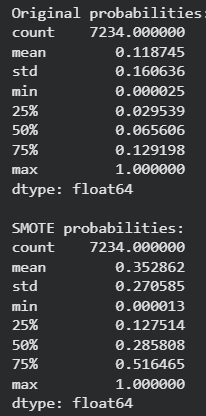